<a href="https://colab.research.google.com/github/ViviNeris/Cases-fiap-IAScientist/blob/main/Case_Fase_1_Fiap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Montando o Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1. Carga e visão geral

Carrega o CSV em um DataFrame. `shape` mostra linhas × colunas, `info()` lista tipos e contagem de valores não nulos por coluna, e `head()` mostra as primeiras linhas para conferir se a leitura está correta.

In [ ]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dados/payflow_credit_risk.csv')

# --- Visão geral ---
print(df.shape)
df.info()
df.head()

(5000, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id_cliente                    5000 non-null   int64  
 1   idade                         5000 non-null   int64  
 2   renda_mensal                  4808 non-null   float64
 3   tempo_emprego_anos            4474 non-null   float64
 4   autonomo                      5000 non-null   int64  
 5   score_credito                 5000 non-null   float64
 6   valor_solicitado              5000 non-null   float64
 7   prazo_meses                   5000 non-null   int64  
 8   juros_mensal_pct              5000 non-null   float64
 9   qtde_cartoes                  5000 non-null   int64  
 10  qtde_contratos_abertos        5000 non-null   int64  
 11  utilizacao_credito            5000 non-null   float64
 12  inadimplencias_anteriores     5000 non-null   int64

,id_cliente,idade,renda_mensal,tempo_emprego_anos,autonomo,score_credito,valor_solicitado,prazo_meses,juros_mensal_pct,qtde_cartoes,...,dias_atraso_max_12m,reclamacoes_6m,possui_avalista,canal_aquisicao,regiao,tipo_produto,parcelas_pagas_ate_3m,atraso_primeira_parcela_dias,status_apos_90d,default_90d
0,1,22,2639.75,2.718888,0,617.0,2619.14,12,3.96,3,...,0,0,0,site,Sul,emprestimo_pessoal,0,29,default,1
1,2,59,2482.34,10.785992,0,619.0,9101.21,36,3.37,2,...,0,0,0,app,Sudeste,cartao,2,10,em_dia,0
2,3,52,6230.69,9.547608,0,665.0,13258.67,48,3.12,0,...,0,0,0,loja,Sudeste,cartao,2,0,em_dia,0
3,4,41,6469.45,4.287084,0,676.0,1407.28,12,1.52,2,...,90,1,0,parceiro,Sudeste,emprestimo_pessoal,3,0,em_dia,0
4,5,40,2343.04,0.000000,0,671.0,2647.92,48,3.07,1,...,15,0,0,app,Nordeste,bnpl,2,10,em_atraso_leve,0


### 2. Existe coluna de data/tempo?
Lista todas as colunas. Serve para checar se há alguma variável temporal, o que
define se é possível fazer split temporal na validação.

Conclusão: Não existe uma coluna de data.

In [ ]:
df.columns.tolist()

['id_cliente',
 'idade',
 'renda_mensal',
 'tempo_emprego_anos',
 'autonomo',
 'score_credito',
 'valor_solicitado',
 'prazo_meses',
 'juros_mensal_pct',
 'qtde_cartoes',
 'qtde_contratos_abertos',
 'utilizacao_credito',
 'inadimplencias_anteriores',
 'dias_atraso_max_12m',
 'reclamacoes_6m',
 'possui_avalista',
 'canal_aquisicao',
 'regiao',
 'tipo_produto',
 'parcelas_pagas_ate_3m',
 'atraso_primeira_parcela_dias',
 'status_apos_90d',
 'default_90d']

### 3. Unidade de análise
`is_unique` retorna True se não há `id_cliente` repetido (uma linha = um cliente).
`value_counts` mostra quantas linhas há por tipo de produto. Isso ajuda a decidir se a unidade é cliente ou contrato/solicitação.

Conclusão:

A Coluna id_cliente é única;

Há 3 tipos de produtos: emprestimo_pessoal, cartao e bnpl

In [ ]:
print(df['id_cliente'].is_unique)
print(df['tipo_produto'].value_counts())

True
tipo_produto
emprestimo_pessoal    2465
cartao                1799
bnpl                   736
Name: count, dtype: int64


### 4. Relação entre target e status pós-90d

`crosstab` cruza duas colunas categóricas e conta as combinações. Mostra como `status_apos_90d` (leakage) se relaciona com `default_90d` (target), ou seja, como o target foi construído.

Conclusão:
- 609 clientes entraram em default em até 90 dias após a concessão.
- 463 clientes estão com atraso leve (premissa: atraso inferior a 90 dias).
- 3.928 clientes estão em dia.
- Todo cliente com status "default" tem default_90d = 1, e todos os outros têm
  default_90d = 0, sem exceção. As duas colunas dizem a mesma coisa.
- status_apos_90d só é conhecida depois dos 90 dias, então é leakage e não pode
  entrar no modelo. O target é default_90d.


In [ ]:
print(pd.crosstab(df['status_apos_90d'], df['default_90d']))

default_90d         0    1
status_apos_90d           
default             0  609
em_atraso_leve    463    0
em_dia           3928    0


Gráfico: clientes por status após 90 dias, separados por default_90d.

O gráfico mostra que todos os clientes com status "default" (≈609) têm
default_90d = 1 (laranja), enquanto os clientes "em_atraso_leve" (≈463) e
"em_dia" (≈3.928) têm default_90d = 0 (azul). Nenhuma barra mistura cores,
ou seja, as duas colunas carregam a mesma informação. Por isso status_apos_90d
é leakage e não pode ser usada no modelo.

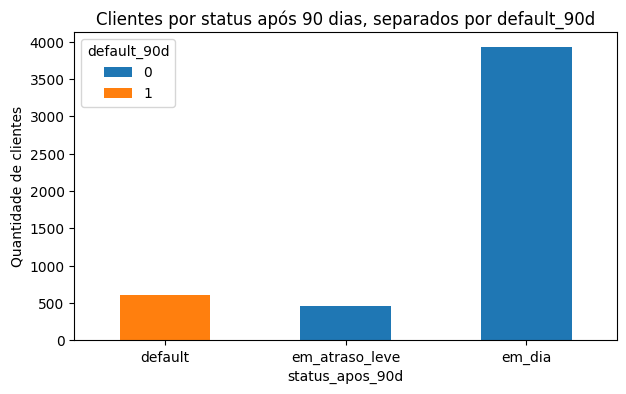

In [ ]:
import matplotlib.pyplot as plt

tabela = pd.crosstab(df['status_apos_90d'], df['default_90d'])

tabela.plot(kind='bar', stacked=True, figsize=(7, 4))
plt.title('Clientes por status após 90 dias, separados por default_90d')
plt.xlabel('status_apos_90d')
plt.ylabel('Quantidade de clientes')
plt.legend(title='default_90d')
plt.xticks(rotation=0)
plt.show()

### 5. Taxa de default (balanceamento do target)

`value_counts()` conta quantos clientes têm default (1) e quantos não (0).

Com `normalize=True` vira proporção. Define se o problema é desbalanceado,
o que afeta a escolha de métricas (acurácia engana nesse caso).

Conclusão:

87,8% dos clientes não entraram em default e 12,2% entraram.

O dado é desbalanceado. Um modelo que dissesse "ninguém dá default" teria ≈88% de acurácia, mas não detectaria nenhum inadimplente. Por isso a acurácia sozinha não serve como métrica, e vamos usar também o recall.

In [ ]:
print(df['default_90d'].value_counts())
print(df['default_90d'].value_counts(normalize=True).round(3))

default_90d
0    4391
1     609
Name: count, dtype: int64
default_90d
0    0.878
1    0.122
Name: proportion, dtype: float64


### 6. Valores ausentes
`isna().sum()` conta os nulos por coluna. Calculamos o percentual e mostramos
só as colunas com nulos. A segunda parte testa uma hipótese de negócio: a
proporção de nulos em `tempo_emprego_anos` é diferente entre autônomos e não autônomos?

Conclusão:

- renda_mensal tem 192 ausentes (3,8%) e tempo_emprego_anos tem 526 (10,5%).
  As demais colunas estão completas.

- Todos os ausentes de tempo_emprego_anos são de clientes autônomos
  (0% entre não autônomos; 65,9% entre autônomos).

- Hipótese: autônomos não têm vínculo formal de emprego, então o campo muitas vezes não se aplica. O ausente tem significado de negócio e não é erro.

In [ ]:
ausentes = df.isna().sum().to_frame('n_ausentes')
ausentes['percentual'] = (ausentes['n_ausentes'] / len(df) * 100).round(1)
print(ausentes[ausentes['n_ausentes'] > 0])

print(df.groupby('autonomo')['tempo_emprego_anos'].apply(lambda s: s.isna().mean()).round(3))

                    n_ausentes  percentual
renda_mensal               192         3.8
tempo_emprego_anos         526        10.5
autonomo
0    0.000
1    0.659
Name: tempo_emprego_anos, dtype: float64


#### 6.1 Conclusão:
Na célula abaixo, os ausentes de renda_mensal (192) se distribuem de forma parecida entre autônomos (3,5%) e não autônomos (3,9%). Não há relação com ser autônomo. A hipótese é que o cliente não declarou a renda (campo declarado).

In [ ]:
print(df.groupby('autonomo')['renda_mensal'].apply(lambda s: s.isna().mean()).round(3))

autonomo
0    0.039
1    0.035
Name: renda_mensal, dtype: float64


### 7. Correlação com o target
Calcula a correlação de cada variável numérica com `default_90d`, ordenada.
Correlações muito altas (próximas de ±1) são suspeitas de leakage: a variável
pode estar carregando informação do futuro.

Conclusão:

- Duas colunas têm relação muito forte com o default: atraso_primeira_parcela_dias (0,86) e parcelas_pagas_ate_3m (-0,79). Forte demais para ser real. Elas só são conhecidas depois que o crédito é concedido, então são leakage e ficam fora do modelo. status_apos_90d também é leakage, mas não aparece aqui porque é texto.

- Todas as outras colunas têm relação fraca com o default (abaixo de 0,3). A mais forte é dias_atraso_max_12m (0,28).

- Isso mostra que prever o default é difícil: nenhuma coluna sozinha basta, então o modelo vai precisar combinar várias.

- id_cliente é só um número de identificação e será ignorado.

In [ ]:
num = df.select_dtypes('number')
print(num.corr()['default_90d'].drop('default_90d').sort_values(ascending=False).round(3))

atraso_primeira_parcela_dias    0.863
dias_atraso_max_12m             0.276
valor_solicitado                0.175
inadimplencias_anteriores       0.106
juros_mensal_pct                0.084
reclamacoes_6m                  0.044
utilizacao_credito              0.036
autonomo                        0.008
id_cliente                      0.004
idade                           0.003
qtde_contratos_abertos          0.000
possui_avalista                -0.008
qtde_cartoes                   -0.011
prazo_meses                    -0.016
tempo_emprego_anos             -0.018
renda_mensal                   -0.082
score_credito                  -0.087
parcelas_pagas_ate_3m          -0.794
Name: default_90d, dtype: float64


### 8. Estatísticas descritivas e outliers
`describe()` resume contagem, média, desvio, mínimo, quartis e máximo de cada coluna numérica. Compare média × mediana e o máximo × percentil 75 para identificar outliers e valores impossíveis (ex.: idade negativa, score fora de 300–900).


Conclusão:

- Não há valores impossíveis: idade (18–70), score (350–900) e utilização (0–1) estão dentro dos limites esperados.

- renda_mensal e valor_solicitado têm cauda longa à direita (média acima da mediana). Os valores altos são raros, mas plausíveis.

- Ambas parecem ter um teto: valor_solicitado em 60.000 e renda_mensal em 35.000 (acúmulo de clientes no valor máximo). Registrar como limitação.

- Contagens menores que 5.000 em renda_mensal e tempo_emprego_anos confirmam os ausentes.

- Decisão sobre tratamento de outliers: Etapa 2.

In [ ]:
print(df.describe().T.round(2))

                               count      mean       std    min      25%  \
id_cliente                    5000.0   2500.50   1443.52    1.0  1250.75   
idade                         5000.0     43.93     15.34   18.0    31.00   
renda_mensal                  4808.0   4692.97   4005.36  800.0  2136.48   
tempo_emprego_anos            4474.0      4.77      3.52    0.0     1.84   
autonomo                      5000.0      0.16      0.37    0.0     0.00   
score_credito                 5000.0    653.59     85.27  350.0   596.00   
valor_solicitado              5000.0  11277.88  10542.62  500.0  4466.43   
prazo_meses                   5000.0     25.44     15.37    6.0    12.00   
juros_mensal_pct              5000.0      2.82      0.93    0.5     2.20   
qtde_cartoes                  5000.0      1.18      1.10    0.0     0.00   
qtde_contratos_abertos        5000.0      1.01      1.01    0.0     0.00   
utilizacao_credito            5000.0      0.33      0.18    0.0     0.19   
inadimplenci

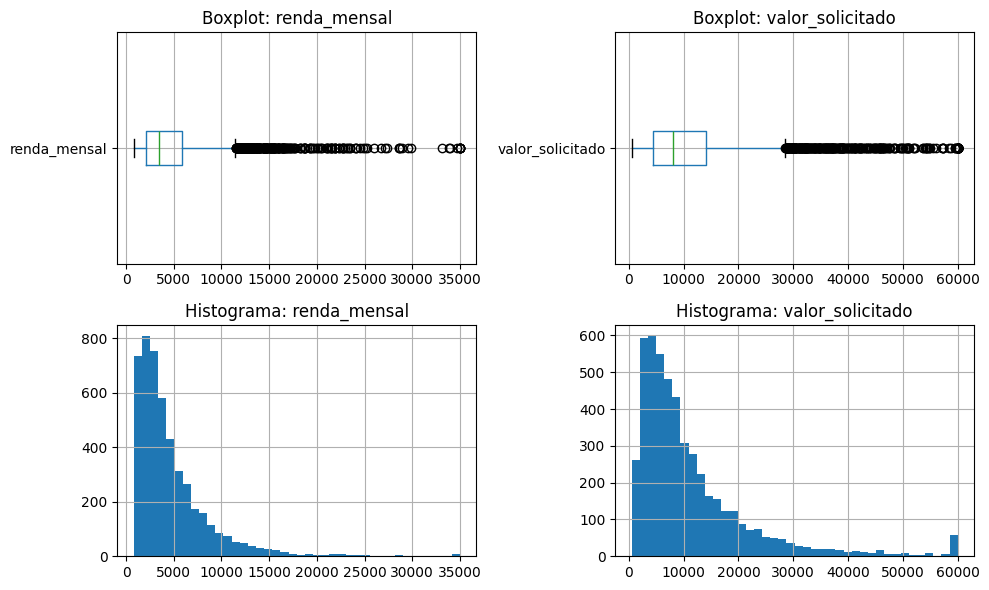

In [ ]:
import matplotlib.pyplot as plt

colunas = ['renda_mensal', 'valor_solicitado']

fig, eixos = plt.subplots(2, 2, figsize=(10, 6))

for i, col in enumerate(colunas):
    df.boxplot(column=col, ax=eixos[0, i], vert=False)
    eixos[0, i].set_title(f'Boxplot: {col}')

    df[col].hist(bins=40, ax=eixos[1, i])
    eixos[1, i].set_title(f'Histograma: {col}')

plt.tight_layout()
plt.show()

In [ ]:
# Avaliando correlação entre 'renda_mensal' e 'valor_solicitado'. O quanto elas andam juntas?
print(df[['renda_mensal', 'valor_solicitado']].corr().round(2))

                  renda_mensal  valor_solicitado
renda_mensal              1.00             -0.01
valor_solicitado         -0.01              1.00


Conclusão da Correlação entre 'renda_mensal' e 'valor_solicitado':

A correlação entre renda_mensal e valor_solicitado é -0,01, ou seja,
não há relação entre as duas. A hipótese de que rendas maiores pedem valores maiores não se confirmou. Isso é coerente com o fato de o dataset ser sintético.

### 9. Hipóteses: default por categoria
Agrupa por uma variável categórica e calcula a taxa média de default em cada grupo (a média de uma coluna 0/1 é a proporção de 1). Troque `canal_aquisicao` por `tipo_produto` ou `regiao` para testar outras hipóteses.

Conclusão:

- tipo_produto: o BNPL tem a maior taxa de default (15,8%). O cartão tem 12,0% e o empréstimo pessoal tem 11,2%. A taxa geral é 12,2%, então o BNPL é o produto que mais se destaca.

- canal_aquisicao: as taxas são parecidas (de 11,5% a 14,4%). O canal parceiro tem a maior (14,4%), mas a diferença é pequena.

- regiao: as taxas também variam pouco (de 10,5% a 13,5%). A região Norte tem a maior (13,5%), mas é um grupo pequeno (333 clientes).

- Nenhuma variável sozinha explica o default. Será preciso combinar várias no modelo.

- Como o dataset não tem coluna de data, não dá para confirmar se a inadimplência subiu ao longo do tempo.

In [ ]:
# Para cada canal de aquisição, qual a taxa de default e quantos clientes vieram por ele
# Mean: Quantos % dos clientes do canal listado entraram em default
# Count: Números de clientes por cada canal
print(df.groupby('canal_aquisicao')['default_90d'].agg(['mean', 'count']).round(3))

                  mean  count
canal_aquisicao              
app              0.115   2231
loja             0.127    746
parceiro         0.144    749
site             0.118   1274


In [ ]:
# Para cada tipo de produto, qual a taxa de default e quantos clientes vieram por ele
# Mean: Quantos % dos clientes com tipo de produto listado entraram em default
# Count: Números de clientes por cada tipo de produto
print(df.groupby('tipo_produto')['default_90d'].agg(['mean', 'count']).round(3))

                     mean  count
tipo_produto                    
bnpl                0.158    736
cartao              0.120   1799
emprestimo_pessoal  0.112   2465


In [ ]:
# Para cada região, qual a taxa de default e quantos clientes vieram por ele
# Mean: Quantos % dos clientes da região listada entraram em default
# Count: Números de clientes por cada região
print(df.groupby('regiao')['default_90d'].agg(['mean', 'count']).round(3))

               mean  count
regiao                    
Centro-Oeste  0.105    611
Nordeste      0.127    956
Norte         0.135    333
Sudeste       0.126   2300
Sul           0.112    800


### 10. Custo aproximado de cada erro

Estima, em reais, quanto a empresa perde ao aprovar um cliente que dá default e quanto deixa de ganhar ao negar um cliente que pagaria.
Premissas (simplificações):

- Perda no default = valor solicitado (sem considerar recuperação na cobrança).

- Ganho com cliente bom = juros simples sobre o valor, pelo prazo todo
  (ignora que o saldo diminui e ignora custos).
A razão perda/ganho diz quantos clientes bons compensam um que dá default.


Conclusão:

A perda média por default (≈ R$ 11.278) é cerca de 1,4 vezes o ganho médio por cliente bom (≈ R$ 8.042). Aprovar quem dá default é o erro mais caro, mas negar um
bom cliente também tem custo relevante.

Atenção: este cálculo é uma estimativa simples, só para ter uma ideia do tamanho dos valores. Eu assumi que, no default, a empresa perde todo o valor emprestado, e que o ganho com um cliente bom é só o juro simples, sem custos. Na vida real isso é mais complexo, então o número exato pode ser diferente.

In [ ]:
# Médias gerais
print(df[['valor_solicitado', 'juros_mensal_pct', 'prazo_meses']].mean().round(2))

# Perda se o cliente der default: assumimos que perde o valor emprestado
perda_media = df['valor_solicitado'].mean()

# Ganho com cliente bom: juros simples ao longo do prazo
ganho_cliente = df['valor_solicitado'] * (df['juros_mensal_pct'] / 100) * df['prazo_meses']
ganho_medio = ganho_cliente.mean()

print('Perda média por default (R$):', round(perda_media))
print('Ganho médio por cliente bom (R$):', round(ganho_medio))
print('Razão perda/ganho:', round(perda_media / ganho_medio, 2))

valor_solicitado    11277.88
juros_mensal_pct        2.82
prazo_meses            25.44
dtype: float64
Perda média por default (R$): 11278
Ganho médio por cliente bom (R$): 8042
Razão perda/ganho: 1.4


#### Matriz de Custos (Considerando a célula 10)

- Aprova cliente bom: + R$ 8.042. Ganho médio com juros.
- Aprova cliente ruim: - R$ 11.278. Perda do valor emprestado (sem recuperação).
- Nega cliente bom: R$ 0. Nada é ganho nem perdido, mas se deixa de ganhar R$ 8.042
  (custo de oportunidade).
- Nega cliente ruim: R$ 0. Perda evitada, sem ganho nem perda.

Conclusão: o erro mais caro é aprovar um cliente que dá default (custo de R$ 11.278), seguido de negar um bom cliente (custo de oportunidade de R$ 8.042). Valores estimados de forma simples, só para dar ordem de grandeza (ver célula 10).

### 11. Separar a coluna alvo e remover colunas que não entram no modelo

Separamos o dataset em duas partes:
- `y`: o que queremos prever (`default_90d`, que vale 1 se o cliente deu default e 0 se não deu).
- `X`: as colunas de entrada, ou seja, as informações que o modelo vai usar para prever.

Para montar o `X`, removemos 6 colunas do dataset original (que tinha 23):

| Coluna removida | Por que saiu |
|---|---|
| `default_90d` | É a resposta que queremos prever. Ela fica no `y`, e não pode ficar nas entradas. |
| `id_cliente` | É só um número de identificação. Não diz nada sobre o risco do cliente. |
| `status_apos_90d` | Leakage: só é conhecida 90 dias depois, e é igual ao target. |
| `parcelas_pagas_ate_3m` | Leakage: só é conhecida depois da concessão do crédito. |
| `atraso_primeira_parcela_dias` | Leakage: só é conhecida depois da concessão do crédito. |
| `juros_mensal_pct` | A taxa costuma ser definida depois de avaliar o risco, então usá-la seria usar a resposta que o modelo deveria descobrir. Decisão a rever se a taxa for fixa por produto. |

Leakage é quando uma coluna traz informação do futuro, que o modelo não teria na hora de
decidir o crédito. Ela deixaria o modelo parecer ótimo no teste e inútil na vida real.

Resultado: 23 colunas − 6 removidas = 17 colunas de entrada (`X.shape` = 5000 × 17).

In [ ]:
y = df['default_90d']

X = df.drop(columns=[
    'default_90d', 'id_cliente',
    'status_apos_90d', 'parcelas_pagas_ate_3m', 'atraso_primeira_parcela_dias',
    'juros_mensal_pct'
])
print(X.shape)

(5000, 17)


### 12. Separar treino e teste (estratificado)

`train_test_split` divide os dados: 80% para treino e 20% para teste.

`stratify=y` mantém a mesma proporção de default nos dois conjuntos.

`random_state=42` faz a divisão ser sempre a mesma, para o resultado ser repetível.

Conclusão:

Os dados foram separados em 4.000 clientes para treino (80%) e 1.000 para teste (20%), ambos com as mesmas 17 colunas de entrada.
A taxa de default ficou em 12,2% nos dois conjuntos, igual à do dataset completo.

Isso mostra que a divisão estratificada funcionou: treino e teste têm a mesma proporção de default, então o modelo terá exemplos suficientes para aprender e a avaliação será mais confiável.

In [ ]:
# Importa a função que separa os dados em treino e teste
from sklearn.model_selection import train_test_split

# A função devolve 4 coisas, na ordem:
#   X_treino: colunas de entrada, parte do treino (80% dos clientes)
#   X_teste:  colunas de entrada, parte do teste (20% dos clientes)
#   y_treino: resposta (default_90d) dos clientes do treino
#   y_teste:  resposta (default_90d) dos clientes do teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,                 # X = colunas de entrada, y = o que queremos prever
    test_size=0.2,        # 20% dos clientes vão para o teste (os outros 80% para o treino)
    stratify=y,           # mantém a mesma proporção de default (12,2%) nos dois conjuntos
    random_state=42       # fixa o sorteio: toda vez que rodar, a divisão é a mesma
)

# Mostra o tamanho de cada conjunto: (linhas, colunas)
print(X_treino.shape, X_teste.shape)

# Média de uma lista de 0 e 1 = proporção de 1 = taxa de default
# round(3) deixa o número com 3 casas decimais (ex.: 0.122 = 12,2%)
print('Default no treino:', y_treino.mean().round(3))
print('Default no teste:', y_teste.mean().round(3))

(4000, 17) (1000, 17)
Default no treino: 0.122
Default no teste: 0.122


### 13. Marcações de valor ausente

Cria duas colunas 0/1 que indicam se o valor estava vazio (1) ou não (0), tanto no treino quanto no teste. Assim o modelo não perde a informação de que o valor estava ausente.

Conclusão:
Foram criadas duas colunas que indicam se o valor estava vazio (1) ou não (0).

No treino, 143 clientes estavam sem renda e 426 estavam sem tempo de emprego.

Assim, o modelo não perde a informação de que o valor estava ausente.Se o ser ausente estiver ligado ao risco, o modelo poderá aprender isso depois.

In [ ]:
# Faz o mesmo processo duas vezes: primeiro com o treino, depois com o teste.
# "base" representa cada um deles na sua vez.
for base in (X_treino, X_teste):

    # base['renda_mensal'].isna() -> para cada cliente, responde True se a renda está vazia
    # .astype(int)               -> transforma True em 1 e False em 0
    # Cria uma nova coluna 'renda_ausente' com esse resultado
    base['renda_ausente'] = base['renda_mensal'].isna().astype(int)

    # Mesma ideia para o tempo de emprego
    base['tempo_emprego_ausente'] = base['tempo_emprego_anos'].isna().astype(int)

# Soma cada coluna nova no treino = quantos clientes tinham o valor vazio
print(X_treino[['renda_ausente', 'tempo_emprego_ausente']].sum())

renda_ausente            143
tempo_emprego_ausente    426
dtype: int64


### 13.1 (Opcional) Estar com o valor ausente tem relação com o default?

Calcula a taxa de default separadamente para dois grupos de clientes do treino: quem tinha o tempo de emprego vazio (1) e quem tinha preenchido (0).

`groupby` separa os clientes nesses dois grupos e `mean()` calcula a média do `y`, que, por ser formado só de 0 e 1, é a proporção de clientes em default em cada grupo.

Serve para ver se a marcação de ausente ajuda a indicar risco.

Conclusão (extra):
a taxa de default é parecida entre quem tinha o tempo de emprego vazio (12,7%) e quem tinha preenchido (12,1%). (IMPORTANTE: Estar ausente, sozinho, não indica maior risco). A marcação foi mantida por ser simples e porque o modelo pode usá-la junto com outras variáveis.

In [ ]:
print(X_treino.groupby('tempo_emprego_ausente').apply(lambda g: y_treino[g.index].mean()).round(3))

tempo_emprego_ausente
0    0.121
1    0.127
dtype: float64


/tmp/ipykernel_415/2263384128.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(X_treino.groupby('tempo_emprego_ausente').apply(lambda g: y_treino[g.index].mean()).round(3))


### 14. Preenchimento, padronização e One-Hot

Organizamos as colunas em 3 grupos:
- Numéricas: vazios preenchidos com a mediana do treino e depois padronizadas.

- 0/1: ficam como estão.

- Texto: viram colunas 0/1 (One-Hot).

`fit_transform` aprende as regras (mediana, escala) **só no treino** e aplica nele.

`transform` aplica essas mesmas regras ao teste, sem reaprender.

Conclusão:

Os dados foram preparados para o modelo: os vazios foram preenchidos com a mediana, as colunas numéricas ficaram em escala parecida e as colunas de texto viraram colunas 0 e 1.

Treino e teste ficaram com 28 colunas cada. As regras foram aprendidas só com o treino e depois aplicadas no teste, para o teste não influenciar o treino.

In [ ]:
# Importa as ferramentas que vamos usar
from sklearn.compose import ColumnTransformer    # É o Organizador de Tratamentos: aplica tratamentos diferentes a grupos de colunas
from sklearn.pipeline import Pipeline            # É a Linha de Montagem: encadeia passos em sequência (primeiro um, depois o outro)
from sklearn.impute import SimpleImputer         # Preenche valores vazios. Troca valores vazios por um valor (aqui, a mediana)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
# StandardScaler: coloca números em escala parecida. É um Padronizador | OneHotEncoder: texto vira colunas 0/1.

# Divide as colunas em 3 grupos, conforme o tratamento que cada uma recebe
numericas = ['idade', 'renda_mensal', 'tempo_emprego_anos', 'score_credito',
             'valor_solicitado', 'prazo_meses', 'qtde_cartoes',
             'qtde_contratos_abertos', 'utilizacao_credito',
             'inadimplencias_anteriores', 'dias_atraso_max_12m', 'reclamacoes_6m']
binarias = ['autonomo', 'possui_avalista', 'renda_ausente', 'tempo_emprego_ausente'] # 0 ou 1
categoricas = ['canal_aquisicao', 'regiao', 'tipo_produto'] # texto

# Monta as regras de tratamento (ainda não executa nada)
preparo = ColumnTransformer([

    # Grupo 1 'num': numéricas passam por 2 passos em sequência
    ('num', Pipeline([
        ('preencher', SimpleImputer(strategy='median')),   # Passo 1: vazios viram a mediana
        ('padronizar', StandardScaler())                   # Passo 2: coloca em escala parecida
    ]), numericas),

    # Grupo 2 'bin': as colunas 0/1 passam sem alteração
    ('bin', 'passthrough', binarias),

    # Grupo 3 'cat': texto vira colunas 0/1 (One-Hot)
    # handle_unknown='ignore': se aparecer uma categoria nova no futuro, não dá erro
    ('cat', OneHotEncoder(handle_unknown='ignore'), categoricas),
])

# fit_transform no TREINO: aprende as regras (mediana, escala) e já aplica
X_treino_pronto = preparo.fit_transform(X_treino)

# transform no TESTE: aplica as MESMAS regras aprendidas no treino, sem reaprender
X_teste_pronto = preparo.transform(X_teste)

# Mostra o tamanho final: (clientes, colunas)
print(X_treino_pronto.shape, X_teste_pronto.shape)

(4000, 28) (1000, 28)
